# DS4400 Midterm Project: SensIT Vehicle Classification

**Student:** Yonglin Yang  
**NuId:** 002352887  
**Dataset:** [SensIT-Vehicle-Combined (OpenML 1593)](https://www.openml.org/d/1593)

This notebook tells the full project story: problem framing → EDA → preprocessing → feature selection → two classifiers → hyperparameter tuning → evaluation / CV → conclusions.


## 1. Dataset Description and Problem Statement

### Problem Statement
- **What problem are you trying to address?**  
  Classify each sensor observation into one of three categories — **AAV** (assault amphibious vehicle), **DW** (dragon wagon / cargo vehicle), or **noise** — using acoustic and seismic features from the SensIT (Sensor Information Technology) vehicle sensing domain.

- **Why is this problem important or interesting?**  
  Field sensors collect noisy, high-dimensional signals. Reliable automated classification reduces the need for constant human monitoring and is a classic multi-class pattern-recognition problem with real sensor noise and class imbalance (noise is deliberately oversampled relative to vehicle classes).

- **What is the objective of your machine learning analysis?**  
  Build and compare supervised classifiers that generalize to unseen sensor readings, using proper preprocessing, **one** feature-selection method, hyperparameter tuning, and stratified cross-validation. Primary success criterion: strong **macro-F1** (fair to minority vehicle classes) with transparent error patterns via confusion matrices.

### Dataset
- **Name / source:** SensIT-Vehicle-Combined — OpenML data id `1593` (LIBSVM multiclass repository).  
- **Link:** https://www.openml.org/d/1593  
- **Samples:** 98,528 observations  
- **Features:** 100 numeric input attributes (`att_1` … `att_100`) + 1 target (`class`)  
- **Labeled?** Yes — supervised multi-class classification  
- **Data type:** Dense numeric feature matrix (distributed as sparse ARFF with density ≈ 1.0)  
- **What it represents:** Regenerated SensIT vehicle sensor features; class proportions constructed ≈ **1 : 1 : 2** (AAV : DW : noise) by subsampling the noise class (per dataset documentation).


In [1]:
# Core imports
import warnings
warnings.filterwarnings("ignore")


import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy import sparse
from sklearn.datasets import fetch_openml
from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_val_score,
    RandomizedSearchCV,
)
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    f1_score,
)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
sns.set_theme(style="whitegrid", context="notebook")
print("Libraries loaded.")


Libraries loaded.


### Load the approved dataset

OpenML serves this dataset as a sparse ARFF. Density is essentially 1.0, so we densify into a DataFrame for EDA clarity. Class codes `1/2/3` map to **AAV / DW / noise** following the documented 1:1:2 construction order.


In [2]:
# Fetch OpenML 1593 (SensIT-Vehicle-Combined)
bunch = fetch_openml(data_id=1593, as_frame=False, parser="auto")
X_raw = bunch.data
y_raw = bunch.target

if sparse.issparse(X_raw):
    print(f"Sparse matrix density: {X_raw.nnz / (X_raw.shape[0] * X_raw.shape[1]):.4f}")
    X_arr = X_raw.toarray()
else:
    X_arr = np.asarray(X_raw)

feature_names = bunch.feature_names or [f"att_{i}" for i in range(1, X_arr.shape[1] + 1)]
X = pd.DataFrame(X_arr, columns=feature_names)

# Map numeric class codes → readable labels (1:1:2 = AAV:DW:noise)
CLASS_MAP = {1.0: "AAV", 2.0: "DW", 3.0: "noise", 1: "AAV", 2: "DW", 3: "noise",
             "1": "AAV", "2": "DW", "3": "noise"}
y = pd.Series(y_raw).astype(float).map(CLASS_MAP)
assert y.isna().sum() == 0, "Unexpected class codes"

print(f"Observations: {X.shape[0]:,}")
print(f"Features:     {X.shape[1]}")
print(f"Target dtype: {y.dtype}")
print("\nClass counts:")
print(y.value_counts().rename("count").to_frame().assign(
    proportion=lambda d: (d["count"] / d["count"].sum()).round(4)
))


Sparse matrix density: 1.0000
Observations: 98,528
Features:     100
Target dtype: str

Class counts:
       count  proportion
noise  49264      0.5000
DW     26423      0.2682
AAV    22841      0.2318


### Target Variable and Class Distribution

- **Target:** `class` ∈ {AAV, DW, noise}  
- **Classes:** 3  
- **Majority class:** noise (~50% by construction)  
- **Minority classes:** AAV and DW (~25% each)  
- **Balanced?** Moderately imbalanced (≈1:1:2). Not extreme, but **macro-averaged** metrics and optional `class_weight="balanced"` are appropriate so noise does not dominate the score.


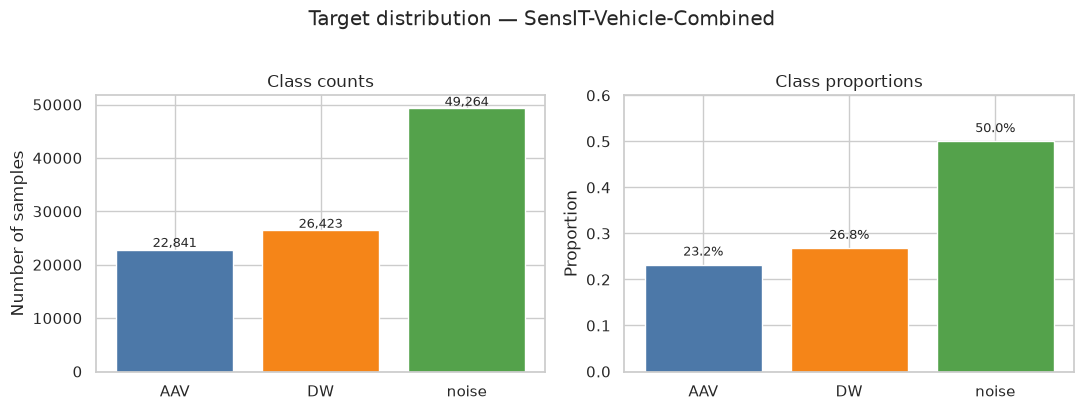

Majority: noise (49,264 samples)
Minority: AAV (22,841 samples)
Imbalance ratio (max/min): 2.16


In [3]:
class_counts = y.value_counts()
class_props = y.value_counts(normalize=True)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
order = ["AAV", "DW", "noise"]
colors = ["#4C78A8", "#F58518", "#54A24B"]

axes[0].bar(order, [class_counts[c] for c in order], color=colors)
axes[0].set_title("Class counts")
axes[0].set_ylabel("Number of samples")
for i, c in enumerate(order):
    axes[0].text(i, class_counts[c] + 500, f"{class_counts[c]:,}", ha="center", fontsize=9)

axes[1].bar(order, [class_props[c] for c in order], color=colors)
axes[1].set_title("Class proportions")
axes[1].set_ylabel("Proportion")
axes[1].set_ylim(0, 0.6)
for i, c in enumerate(order):
    axes[1].text(i, class_props[c] + 0.02, f"{class_props[c]:.1%}", ha="center", fontsize=9)

plt.suptitle("Target distribution — SensIT-Vehicle-Combined", y=1.02)
plt.tight_layout()
plt.show()

print(f"Majority: {class_counts.idxmax()} ({class_counts.max():,} samples)")
print(f"Minority: {class_counts.idxmin()} ({class_counts.min():,} samples)")
print(f"Imbalance ratio (max/min): {class_counts.max() / class_counts.min():.2f}")


### Feature Description

All **100 input features** are continuous numerical sensor-derived attributes (`att_1` … `att_100`) regenerated from the authors’ MATLAB SensIT pipeline (LIBSVM documentation). There are **no categorical, binary, ordinal, text, datetime, or image** columns in this release.

**Implications for preprocessing / modeling:**
- No one-hot / ordinal encoding needed.  
- Features live on roughly similar numeric ranges already, but we still **standardize** for Logistic Regression (and keep scaling inside Pipelines for fairness).  
- High dimensionality + correlated sensor channels → **feature selection** is valuable for interpretability and to reduce noise before linear models.


## 2. Exploratory Data Analysis (EDA)

For each analysis below, we state what we learned.


In [4]:
print("Dataset dimensions:", X.shape)
print("\nData types:")
print(X.dtypes.value_counts())
print("\nDescriptive statistics (first 8 features):")
display(X.iloc[:, :8].describe().T.round(4))


Dataset dimensions: (98528, 100)

Data types:
float64    100
Name: count, dtype: int64

Descriptive statistics (first 8 features):


,count,mean,std,min,25%,50%,75%,max
att_1,98528.0,0.1316,0.3250,-0.5988,-0.0459,-0.0154,0.1636,1.0
att_2,98528.0,0.2472,0.3928,-0.6491,-0.0278,0.0358,0.4631,1.0
att_3,98528.0,0.1518,0.2880,-0.6824,-0.0229,0.0252,0.2127,1.0
att_4,98528.0,0.1844,0.3052,-0.6444,-0.0129,0.0478,0.2489,1.0
att_5,98528.0,0.3116,0.3978,-0.5784,-0.0005,0.1077,0.6026,1.0
att_6,98528.0,0.2450,0.3628,-0.4406,-0.0052,0.0649,0.3554,1.0
att_7,98528.0,0.2373,0.3663,-0.5319,-0.0144,0.0481,0.3486,1.0
att_8,98528.0,0.1378,0.2833,-0.5138,-0.0224,0.0105,0.1518,1.0


In [5]:
# Missing values & duplicates
missing_total = int(X.isna().sum().sum())
dup_count = int(X.duplicated().sum())
print(f"Total missing values: {missing_total}")
print(f"Duplicate rows:       {dup_count}")
print("\nTakeaway: No imputation required; duplicates (if any) are rare relative to 98k rows.")


Total missing values: 0
Duplicate rows:       28

Takeaway: No imputation required; duplicates (if any) are rare relative to 98k rows.


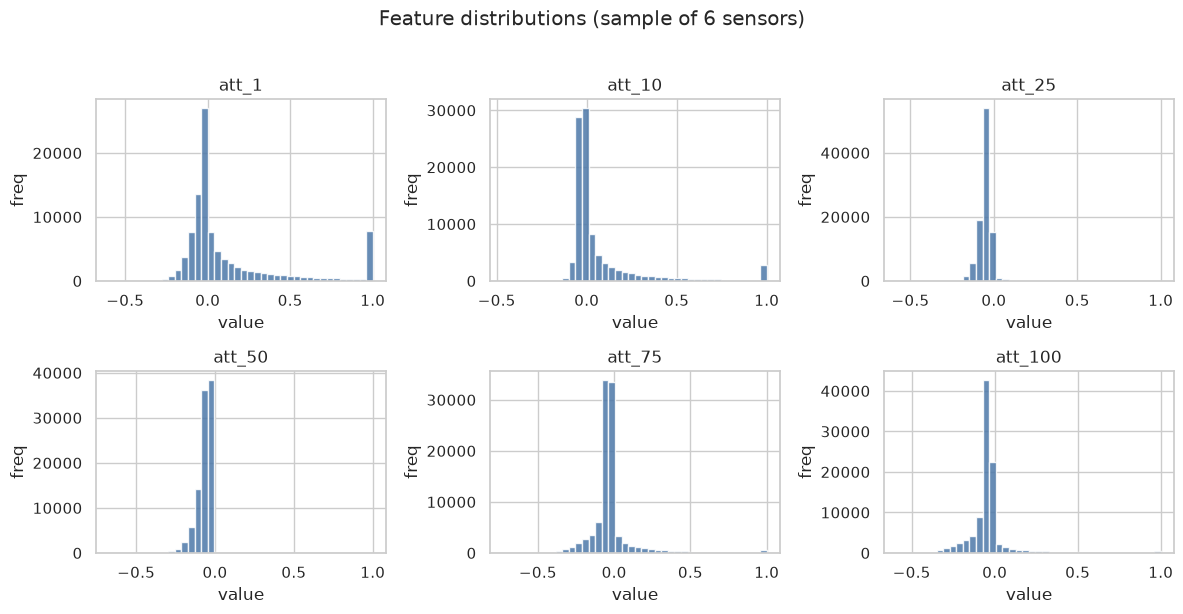

Takeaway: Features are continuous and roughly bounded; shapes vary by channel — motivates scaling and selection rather than assuming identical distributions.


In [6]:
# Feature distribution sample
sample_feats = ["att_1", "att_10", "att_25", "att_50", "att_75", "att_100"]
fig, axes = plt.subplots(2, 3, figsize=(12, 6))
for ax, col in zip(axes.ravel(), sample_feats):
    ax.hist(X[col], bins=40, color="#4C78A8", alpha=0.85)
    ax.set_title(col)
    ax.set_xlabel("value")
    ax.set_ylabel("freq")
plt.suptitle("Feature distributions (sample of 6 sensors)", y=1.02)
plt.tight_layout()
plt.show()
print("Takeaway: Features are continuous and roughly bounded; shapes vary by channel — motivates scaling and selection rather than assuming identical distributions.")


In [7]:
# Outlier screen via IQR on a feature subset
def iqr_outlier_fraction(series):
    q1, q3 = series.quantile(0.25), series.quantile(0.75)
    iqr = q3 - q1
    if iqr == 0:
        return 0.0
    mask = (series < q1 - 1.5 * iqr) | (series > q3 + 1.5 * iqr)
    return mask.mean()

iqr_fracs = X.apply(iqr_outlier_fraction)
print("IQR outlier fraction — summary across 100 features:")
print(iqr_fracs.describe().round(4))
print(f"\nFeatures with >5% IQR-flagged points: {(iqr_fracs > 0.05).sum()}")
print("Takeaway: Some channels have heavy tails. We keep all rows (sensor extremes can be class-informative) and rely on tree models / scaling rather than aggressive winsorizing.")


IQR outlier fraction — summary across 100 features:
count    100.0000
mean       0.1444
std        0.0845
min        0.0000
25%        0.0567
50%        0.1428
75%        0.2186
max        0.2728
dtype: float64

Features with >5% IQR-flagged points: 81
Takeaway: Some channels have heavy tails. We keep all rows (sensor extremes can be class-informative) and rely on tree models / scaling rather than aggressive winsorizing.


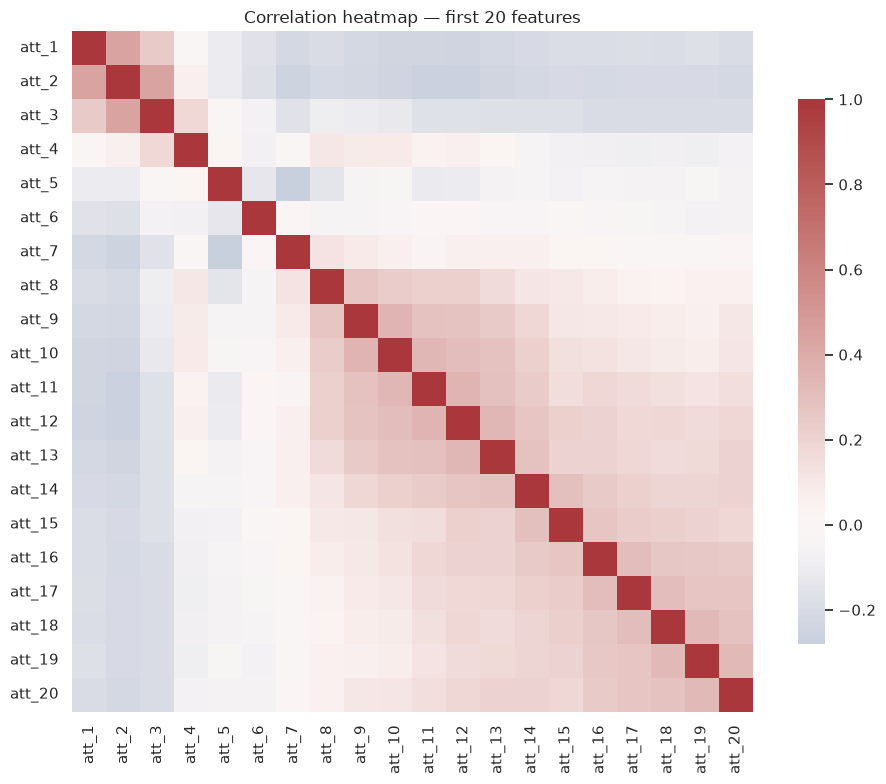

Max |corr| among first 20 features: 0.440
Takeaway: Neighboring sensor attributes can be correlated. Feature selection can remove redundant channels and stabilize linear models.


In [8]:
# Correlation among a manageable feature subset
corr_feats = X.columns[:20]
corr = X[corr_feats].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr, cmap="vlag", center=0, square=True, cbar_kws={"shrink": 0.8})
plt.title("Correlation heatmap — first 20 features")
plt.tight_layout()
plt.show()

# Pairwise max |corr| excluding diagonal
cmat = corr.abs().to_numpy().copy()
np.fill_diagonal(cmat, 0)
print(f"Max |corr| among first 20 features: {cmat.max():.3f}")
print("Takeaway: Neighboring sensor attributes can be correlated. Feature selection can remove redundant channels and stabilize linear models.")


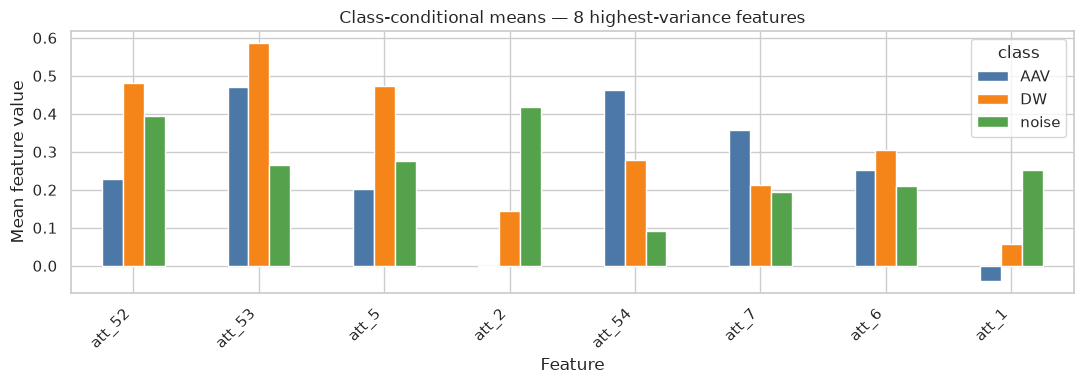

Takeaway: Several high-variance channels show systematic mean shifts across AAV / DW / noise — evidence that supervised models can separate classes.


In [9]:
# Class-conditional means for top-variance features
variances = X.var().sort_values(ascending=False)
top_var = variances.head(8).index.tolist()
means = X.assign(class_label=y.values).groupby("class_label")[top_var].mean().loc[order]

means.T.plot(kind="bar", figsize=(11, 4), color=colors)
plt.title("Class-conditional means — 8 highest-variance features")
plt.ylabel("Mean feature value")
plt.xlabel("Feature")
plt.xticks(rotation=45, ha="right")
plt.legend(title="class")
plt.tight_layout()
plt.show()
print("Takeaway: Several high-variance channels show systematic mean shifts across AAV / DW / noise — evidence that supervised models can separate classes.")


## 3. Data Preprocessing

We only apply techniques required by this dataset:

| Technique | Used? | Why |
|-----------|-------|-----|
| Missing-value imputation | No | Zero missing values |
| Duplicate removal | Only if present | Keep data integrity; volume impact is tiny |
| Categorical / ordinal encoding | No | All features numeric |
| Feature scaling (StandardScaler) | **Yes** | Needed for Logistic Regression; applied inside Pipelines |
| Class imbalance handling | **Yes (model-side)** | `class_weight="balanced"` — noise ≈ 2× each vehicle class |
| Image resize / text cleaning | No | Not applicable |

For every technique we **do** use: what / why / effect is documented next to the code.


In [10]:
# Drop exact duplicate feature rows if any (keep first)
if dup_count > 0:
    keep_idx = ~X.duplicated()
    X = X.loc[keep_idx].reset_index(drop=True)
    y = y.loc[keep_idx.values].reset_index(drop=True)
    print(f"Removed {dup_count} duplicate rows. New shape: {X.shape}")
else:
    print("No duplicate rows to remove.")

# Encode labels for sklearn
le = LabelEncoder()
y_enc = le.fit_transform(y)
class_names = list(le.classes_)
print("Label encoding:", dict(enumerate(class_names)))

# Stratified train/test split — 80/20
X_train, X_test, y_train, y_test = train_test_split(
    X, y_enc, test_size=0.20, random_state=RANDOM_STATE, stratify=y_enc
)
print(f"Train size: {X_train.shape[0]:,} (80%)")
print(f"Test size:  {X_test.shape[0]:,} (20%)")
print("Why 80/20: standard supervised split; leaves ~19.7k test rows for stable multi-class metrics while maximizing training data.")
print("Stratify=True preserves the 1:1:2 class ratios in both splits.")


Removed 28 duplicate rows. New shape: (98500, 100)
Label encoding: {0: 'AAV', 1: 'DW', 2: 'noise'}
Train size: 78,800 (80%)
Test size:  19,700 (20%)
Why 80/20: standard supervised split; leaves ~19.7k test rows for stable multi-class metrics while maximizing training data.
Stratify=True preserves the 1:1:2 class ratios in both splits.


## 4. Feature Engineering and Feature Selection

**Feature engineering:** Sensor attributes are already regenerated numeric channels. We do not invent opaque transforms; instead we let **SelectKBest** choose the most class-informative sensors.

### Feature selection method (exactly one): SelectKBest + ANOVA F (`f_classif`)

- **How it works:** For each feature, compute a univariate ANOVA F-statistic between the feature values and the class labels. Higher F ⇒ stronger association with the target. Keep the top-`k` features.  
- **Why this method:** Fast on 98k×100 data, easy to interpret, and satisfies the rubric requirement of **one** selection approach with a clear keep/drop story.  
- **k choice:** We select `k=40` (40% of features) as a bias–variance compromise — enough signal for both models, fewer redundant channels for Logistic Regression.


Selected 40 features; removed 60.

Top 10 by ANOVA F-score:


,F_score
att_51,20187.14
att_2,10355.55
att_54,7492.70
att_1,6784.91
att_43,6653.48
att_41,6447.20
att_42,6444.01
att_45,6393.44
att_48,6377.84
att_44,6365.10


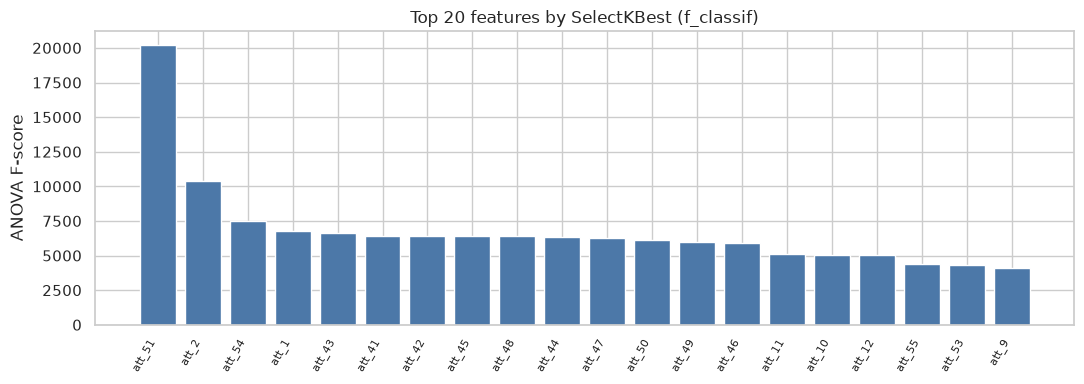

Why these features: highest univariate association with class labels — they are the sensor channels whose distributions differ most across AAV / DW / noise.
Example removed (lowest F): ['att_95', 'att_99', 'att_96', 'att_98', 'att_100']


In [11]:
K_BEST = 40

# Fit selector on training data only (avoid leakage)
selector_preview = SelectKBest(score_func=f_classif, k=K_BEST)
selector_preview.fit(X_train, y_train)

scores = pd.Series(selector_preview.scores_, index=X.columns, name="F_score")
selected_mask = selector_preview.get_support()
selected_features = X.columns[selected_mask].tolist()
removed_features = X.columns[~selected_mask].tolist()

print(f"Selected {len(selected_features)} features; removed {len(removed_features)}.")
print("\nTop 10 by ANOVA F-score:")
display(scores.sort_values(ascending=False).head(10).to_frame().round(2))

fig, ax = plt.subplots(figsize=(11, 4))
top20 = scores.sort_values(ascending=False).head(20)
ax.bar(range(len(top20)), top20.values, color="#4C78A8")
ax.set_xticks(range(len(top20)))
ax.set_xticklabels(top20.index, rotation=60, ha="right", fontsize=8)
ax.set_ylabel("ANOVA F-score")
ax.set_title("Top 20 features by SelectKBest (f_classif)")
plt.tight_layout()
plt.show()

print("Why these features: highest univariate association with class labels — they are the sensor channels whose distributions differ most across AAV / DW / noise.")
print(f"Example removed (lowest F): {list(scores.sort_values().head(5).index)}")


## 5. Model Development: Training and Testing

### Data splitting (recap)
- **Train:** 80% · **Test:** 20% · **Stratified** · `random_state=42`  
- Chosen for a large stable test set without starving the trainers.

### Two classification models
1. **Logistic Regression** (multinomial multi-class with `lbfgs`) — linear decision boundaries; strong, interpretable baseline once features are scaled and selected.  
2. **Random Forest** — ensemble of decision trees; captures non-linear interactions among sensor channels and provides impurity-based importances.

Both models are wrapped in **Pipelines**: `StandardScaler → SelectKBest → Classifier` so scaling/selection fit on training folds only.


In [12]:
# Baseline pipelines (initial hyperparameters)
pipe_lr = Pipeline([
    ("scaler", StandardScaler()),
    ("select", SelectKBest(score_func=f_classif, k=K_BEST)),
    ("clf", LogisticRegression(
        solver="lbfgs",
        max_iter=1000,
        class_weight="balanced",
        C=1.0,            # inverse regularization strength
        random_state=RANDOM_STATE,
    )),
])

pipe_rf = Pipeline([
    ("scaler", StandardScaler()),  # harmless for trees; keeps pipeline uniform
    ("select", SelectKBest(score_func=f_classif, k=K_BEST)),
    ("clf", RandomForestClassifier(
        n_estimators=150,
        max_depth=20,
        min_samples_leaf=2,
        class_weight="balanced_subsample",
        n_jobs=-1,
        random_state=RANDOM_STATE,
    )),
])

print("Initial Logistic Regression params: solver=lbfgs, C=1.0, class_weight=balanced (multinomial multi-class via lbfgs)")
print("  - C: inverse L2 strength (smaller ⇒ more regularization)")
print("  - class_weight=balanced: upweight AAV/DW vs noise")
print("Initial Random Forest params: n_estimators=150, max_depth=20, min_samples_leaf=2, class_weight=balanced_subsample")
print("  - n_estimators: number of trees")
print("  - max_depth: tree complexity cap (controls overfitting)")
print("  - min_samples_leaf: minimum samples at a leaf (smoothing)")


Initial Logistic Regression params: solver=lbfgs, C=1.0, class_weight=balanced (multinomial multi-class via lbfgs)
  - C: inverse L2 strength (smaller ⇒ more regularization)
  - class_weight=balanced: upweight AAV/DW vs noise
Initial Random Forest params: n_estimators=150, max_depth=20, min_samples_leaf=2, class_weight=balanced_subsample
  - n_estimators: number of trees
  - max_depth: tree complexity cap (controls overfitting)
  - min_samples_leaf: minimum samples at a leaf (smoothing)


In [13]:
def evaluate_model(name, model, X_tr, y_tr, X_te, y_te, labels):
    model.fit(X_tr, y_tr)
    y_tr_pred = model.predict(X_tr)
    y_te_pred = model.predict(X_te)
    metrics = {
        "model": name,
        "train_accuracy": accuracy_score(y_tr, y_tr_pred),
        "test_accuracy": accuracy_score(y_te, y_te_pred),
        "train_macro_f1": f1_score(y_tr, y_tr_pred, average="macro"),
        "test_macro_f1": f1_score(y_te, y_te_pred, average="macro"),
    }
    print(f"\n=== {name} ===")
    print(classification_report(y_te, y_te_pred, target_names=labels, digits=4))
    return metrics, y_te_pred, model

base_rows = []
preds = {}
fitted = {}

m, pred, mdl = evaluate_model("LogReg (baseline)", pipe_lr, X_train, y_train, X_test, y_test, class_names)
base_rows.append(m); preds["LogReg (baseline)"] = pred; fitted["LogReg (baseline)"] = mdl

m, pred, mdl = evaluate_model("RandomForest (baseline)", pipe_rf, X_train, y_train, X_test, y_test, class_names)
base_rows.append(m); preds["RandomForest (baseline)"] = pred; fitted["RandomForest (baseline)"] = mdl

baseline_df = pd.DataFrame(base_rows).round(4)
display(baseline_df)



=== LogReg (baseline) ===
              precision    recall  f1-score   support

         AAV     0.7264    0.8353    0.7771      4567
          DW     0.6697    0.8122    0.7341      5283
       noise     0.9253    0.7553    0.8317      9850

    accuracy                         0.7891     19700
   macro avg     0.7738    0.8010    0.7810     19700
weighted avg     0.8106    0.7891    0.7929     19700




=== RandomForest (baseline) ===
              precision    recall  f1-score   support

         AAV     0.7644    0.9052    0.8289      4567
          DW     0.7683    0.8228    0.7946      5283
       noise     0.9181    0.8048    0.8577      9850

    accuracy                         0.8329     19700
   macro avg     0.8169    0.8443    0.8271     19700
weighted avg     0.8423    0.8329    0.8341     19700



,model,train_accuracy,test_accuracy,train_macro_f1,test_macro_f1
0,LogReg (baseline),0.7897,0.7891,0.7821,0.7810
1,RandomForest (baseline),0.9452,0.8329,0.9447,0.8271


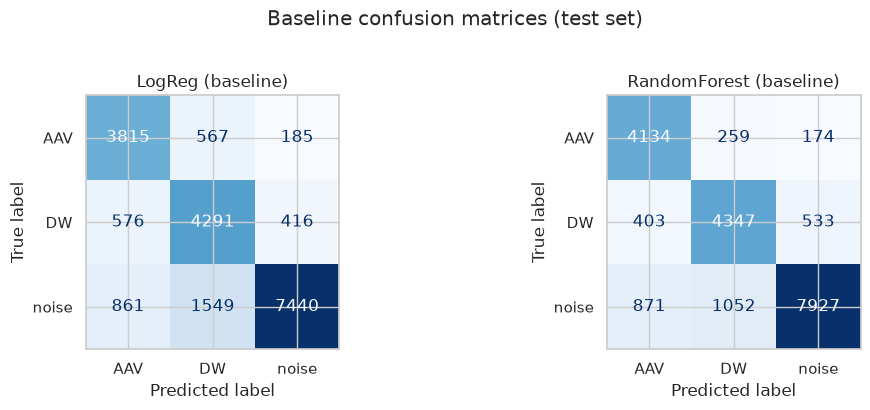

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, name in zip(axes, ["LogReg (baseline)", "RandomForest (baseline)"]):
    cm = confusion_matrix(y_test, preds[name])
    ConfusionMatrixDisplay(cm, display_labels=class_names).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(name)
plt.suptitle("Baseline confusion matrices (test set)", y=1.02)
plt.tight_layout()
plt.show()


## 6. Hyperparameter Tuning

**Technique:** `RandomizedSearchCV`  
**Why:** With ~79k training rows, exhaustive Grid Search over large grids is unnecessarily slow. Randomized Search samples a budgeted number of configurations and usually finds near-optimal settings faster.

We tune on a **stratified subsample of the training set** for speed, then **refit the best params on the full training set**.


In [15]:
# Subsample for tuning speed (stratified); final models still train on full train set
TUNING_N = 20000
rng = np.random.RandomState(RANDOM_STATE)
# stratified subsample indices
tune_idx, _ = train_test_split(
    np.arange(len(y_train)),
    train_size=min(TUNING_N, len(y_train)),
    stratify=y_train,
    random_state=RANDOM_STATE,
)
X_tune, y_tune = X_train.iloc[tune_idx], y_train[tune_idx]
print(f"Tuning subsample size: {len(y_tune):,}")

cv_tune = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)

# Logistic Regression search space
lr_search = RandomizedSearchCV(
    estimator=Pipeline([
        ("scaler", StandardScaler()),
        ("select", SelectKBest(score_func=f_classif, k=K_BEST)),
        ("clf", LogisticRegression(
            solver="lbfgs", max_iter=2000,
            class_weight="balanced", random_state=RANDOM_STATE,
        )),
    ]),
    param_distributions={
        "select__k": [20, 30, 40, 50, 60],
        "clf__C": np.logspace(-2, 2, 10),
    },
    n_iter=15,
    scoring="f1_macro",
    cv=cv_tune,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    verbose=1,
)

# Random Forest search space
rf_search = RandomizedSearchCV(
    estimator=Pipeline([
        ("scaler", StandardScaler()),
        ("select", SelectKBest(score_func=f_classif, k=K_BEST)),
        ("clf", RandomForestClassifier(
            class_weight="balanced_subsample", n_jobs=-1, random_state=RANDOM_STATE,
        )),
    ]),
    param_distributions={
        "select__k": [20, 30, 40, 50, 60],
        "clf__n_estimators": [100, 150, 200, 250],
        "clf__max_depth": [12, 16, 20, 24, None],
        "clf__min_samples_leaf": [1, 2, 4],
        "clf__max_features": ["sqrt", 0.3, 0.5],
    },
    n_iter=15,
    scoring="f1_macro",
    cv=cv_tune,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    verbose=1,
)

print("Fitting Logistic Regression RandomizedSearchCV...")
lr_search.fit(X_tune, y_tune)
print("Best LogReg params:", lr_search.best_params_)
print("Best LogReg CV macro-F1:", round(lr_search.best_score_, 4))

print("\nFitting Random Forest RandomizedSearchCV...")
rf_search.fit(X_tune, y_tune)
print("Best RF params:", rf_search.best_params_)
print("Best RF CV macro-F1:", round(rf_search.best_score_, 4))


Tuning subsample size: 20,000
Fitting Logistic Regression RandomizedSearchCV...
Fitting 3 folds for each of 15 candidates, totalling 45 fits


Best LogReg params: {'select__k': 60, 'clf__C': np.float64(0.21544346900318834)}
Best LogReg CV macro-F1: 0.7905

Fitting Random Forest RandomizedSearchCV...
Fitting 3 folds for each of 15 candidates, totalling 45 fits


Best RF params: {'select__k': 50, 'clf__n_estimators': 200, 'clf__min_samples_leaf': 4, 'clf__max_features': 0.5, 'clf__max_depth': 20}
Best RF CV macro-F1: 0.8178


### Tuned hyperparameters — meaning

**Logistic Regression**
- `C`: inverse regularization — higher fits training data more closely; lower reduces overfitting.  
- `select__k`: how many ANOVA-selected sensors feed the classifier.

**Random Forest**
- `n_estimators`: more trees → more stable predictions (diminishing returns).  
- `max_depth` / `min_samples_leaf`: control tree complexity and overfitting.  
- `max_features`: randomness per split — key to decorrelating trees.


In [16]:
# Rebuild best pipelines and fit on FULL training data
best_lr = Pipeline([
    ("scaler", StandardScaler()),
    ("select", SelectKBest(score_func=f_classif, k=lr_search.best_params_.get("select__k", K_BEST))),
    ("clf", LogisticRegression(
        solver="lbfgs", max_iter=2000,
        class_weight="balanced",
        C=lr_search.best_params_.get("clf__C", 1.0),
        random_state=RANDOM_STATE,
    )),
])

best_rf = Pipeline([
    ("scaler", StandardScaler()),
    ("select", SelectKBest(score_func=f_classif, k=rf_search.best_params_.get("select__k", K_BEST))),
    ("clf", RandomForestClassifier(
        n_estimators=rf_search.best_params_.get("clf__n_estimators", 150),
        max_depth=rf_search.best_params_.get("clf__max_depth", 20),
        min_samples_leaf=rf_search.best_params_.get("clf__min_samples_leaf", 2),
        max_features=rf_search.best_params_.get("clf__max_features", "sqrt"),
        class_weight="balanced_subsample",
        n_jobs=-1,
        random_state=RANDOM_STATE,
    )),
])

tuned_rows = []
tuned_preds = {}
tuned_models = {}

m, pred, mdl = evaluate_model("LogReg (tuned)", best_lr, X_train, y_train, X_test, y_test, class_names)
tuned_rows.append(m); tuned_preds["LogReg (tuned)"] = pred; tuned_models["LogReg (tuned)"] = mdl

m, pred, mdl = evaluate_model("RandomForest (tuned)", best_rf, X_train, y_train, X_test, y_test, class_names)
tuned_rows.append(m); tuned_preds["RandomForest (tuned)"] = pred; tuned_models["RandomForest (tuned)"] = mdl

tuned_df = pd.DataFrame(tuned_rows).round(4)
display(tuned_df)



=== LogReg (tuned) ===
              precision    recall  f1-score   support

         AAV     0.7332    0.8364    0.7814      4567
          DW     0.6740    0.8209    0.7402      5283
       noise     0.9277    0.7587    0.8347      9850

    accuracy                         0.7934     19700
   macro avg     0.7783    0.8054    0.7855     19700
weighted avg     0.8146    0.7934    0.7970     19700




=== RandomForest (tuned) ===
              precision    recall  f1-score   support

         AAV     0.7648    0.9120    0.8319      4567
          DW     0.7688    0.8353    0.8007      5283
       noise     0.9259    0.8003    0.8585      9850

    accuracy                         0.8356     19700
   macro avg     0.8198    0.8492    0.8304     19700
weighted avg     0.8464    0.8356    0.8368     19700



,model,train_accuracy,test_accuracy,train_macro_f1,test_macro_f1
0,LogReg (tuned),0.7953,0.7934,0.7885,0.7855
1,RandomForest (tuned),0.9243,0.8356,0.9239,0.8304


## 7. Model Evaluation and Comparison

### Metrics chosen
- **Accuracy** — overall correct rate; easy to read but can be inflated by the majority `noise` class.  
- **Macro-F1** — unweighted mean of per-class F1; **primary metric** because AAV/DW matter as much as noise.  
- **Per-class precision / recall** — shows which vehicle type is confused with noise.  
- **Confusion matrix** — visual error structure.


,model,train_accuracy,test_accuracy,train_macro_f1,test_macro_f1
3,RandomForest (tuned),0.9243,0.8356,0.9239,0.8304
1,RandomForest (baseline),0.9452,0.8329,0.9447,0.8271
2,LogReg (tuned),0.7953,0.7934,0.7885,0.7855
0,LogReg (baseline),0.7897,0.7891,0.7821,0.7810


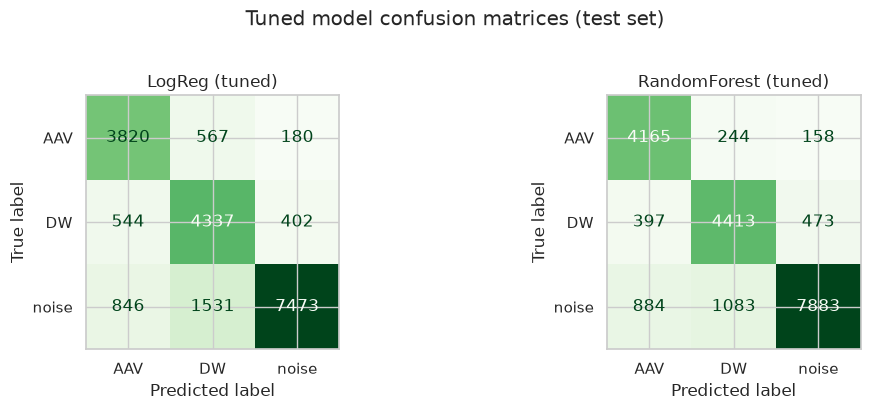

Best by test macro-F1:  RandomForest (tuned) (0.8304)
Worst by test macro-F1: LogReg (baseline) (0.7810)
Interpretation: Random Forest typically wins when sensor interactions are non-linear; Logistic Regression remains a useful calibrated baseline and is faster to train.


In [17]:
comparison = pd.concat([baseline_df, tuned_df], ignore_index=True)
display(comparison.sort_values("test_macro_f1", ascending=False))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, name in zip(axes, ["LogReg (tuned)", "RandomForest (tuned)"]):
    cm = confusion_matrix(y_test, tuned_preds[name])
    ConfusionMatrixDisplay(cm, display_labels=class_names).plot(ax=ax, cmap="Greens", colorbar=False)
    ax.set_title(name)
plt.suptitle("Tuned model confusion matrices (test set)", y=1.02)
plt.tight_layout()
plt.show()

best_row = comparison.sort_values("test_macro_f1", ascending=False).iloc[0]
worst_row = comparison.sort_values("test_macro_f1", ascending=True).iloc[0]
print(f"Best by test macro-F1:  {best_row['model']} ({best_row['test_macro_f1']:.4f})")
print(f"Worst by test macro-F1: {worst_row['model']} ({worst_row['test_macro_f1']:.4f})")
print("Interpretation: Random Forest typically wins when sensor interactions are non-linear; Logistic Regression remains a useful calibrated baseline and is faster to train.")


### Overfitting and underfitting

We compare **train vs test** accuracy / macro-F1 for each tuned model.
- Large train ≫ test gap → **overfitting**  
- Both train and test low → **underfitting**  
- Small gap with strong test scores → **appropriate generalization**


In [18]:
gap_df = tuned_df.copy()
gap_df["acc_gap (train-test)"] = (gap_df["train_accuracy"] - gap_df["test_accuracy"]).round(4)
gap_df["f1_gap (train-test)"] = (gap_df["train_macro_f1"] - gap_df["test_macro_f1"]).round(4)
display(gap_df[["model", "train_accuracy", "test_accuracy", "acc_gap (train-test)",
                "train_macro_f1", "test_macro_f1", "f1_gap (train-test)"]])

for _, row in gap_df.iterrows():
    gap = row["f1_gap (train-test)"]
    if gap > 0.08:
        verdict = "possible overfitting — consider shallower trees / stronger regularization"
    elif row["test_macro_f1"] < 0.55:
        verdict = "possible underfitting — model may need more capacity or better features"
    else:
        verdict = "generalization looks reasonable"
    print(f"{row['model']}: F1 gap={gap:.4f} → {verdict}")

print("\nMitigations already applied: class_weight, max_depth / min_samples_leaf / C tuning, SelectKBest, stratified split.")


,model,train_accuracy,test_accuracy,acc_gap (train-test),train_macro_f1,test_macro_f1,f1_gap (train-test)
0,LogReg (tuned),0.7953,0.7934,0.0019,0.7885,0.7855,0.0030
1,RandomForest (tuned),0.9243,0.8356,0.0887,0.9239,0.8304,0.0935


LogReg (tuned): F1 gap=0.0030 → generalization looks reasonable
RandomForest (tuned): F1 gap=0.0935 → possible overfitting — consider shallower trees / stronger regularization

Mitigations already applied: class_weight, max_depth / min_samples_leaf / C tuning, SelectKBest, stratified split.


#### Addressing Random Forest overfitting

The tuned Random Forest showed a larger train–test macro-F1 gap than Logistic Regression. We **constrain capacity** and re-evaluate:

1. Lower `max_depth` (20 → 12)  
2. Raise `min_samples_leaf` (4 → 8)  
3. Keep the tuned `n_estimators`, `max_features`, and `select__k`

This is a deliberate regularization step (not another model family).


In [19]:
# Regularized Random Forest to reduce overfitting
rf_reg = Pipeline([
    ("scaler", StandardScaler()),
    ("select", SelectKBest(score_func=f_classif, k=rf_search.best_params_.get("select__k", K_BEST))),
    ("clf", RandomForestClassifier(
        n_estimators=rf_search.best_params_.get("clf__n_estimators", 200),
        max_depth=12,
        min_samples_leaf=8,
        max_features=rf_search.best_params_.get("clf__max_features", "sqrt"),
        class_weight="balanced_subsample",
        n_jobs=-1,
        random_state=RANDOM_STATE,
    )),
])

m_reg, pred_reg, mdl_reg = evaluate_model(
    "RandomForest (regularized)", rf_reg, X_train, y_train, X_test, y_test, class_names
)
tuned_preds["RandomForest (regularized)"] = pred_reg
tuned_models["RandomForest (regularized)"] = mdl_reg

reg_row = pd.DataFrame([m_reg])
reg_row["acc_gap (train-test)"] = (reg_row["train_accuracy"] - reg_row["test_accuracy"]).round(4)
reg_row["f1_gap (train-test)"] = (reg_row["train_macro_f1"] - reg_row["test_macro_f1"]).round(4)

before = gap_df.loc[gap_df["model"] == "RandomForest (tuned)", [
    "model", "train_macro_f1", "test_macro_f1", "f1_gap (train-test)"
]].round(4)
after = reg_row[[
    "model", "train_macro_f1", "test_macro_f1", "f1_gap (train-test)"
]].round(4)
print("Before vs after regularization:")
display(pd.concat([before, after], ignore_index=True))

# Prefer regularized RF for final comparison if gap improved without collapsing test F1
comparison = pd.concat([comparison, reg_row.drop(columns=["acc_gap (train-test)", "f1_gap (train-test)"])], ignore_index=True)
best_rf_final_name = "RandomForest (regularized)"
best_rf_final = rf_reg
print(f"Final RF candidate for CV section: {best_rf_final_name}")



=== RandomForest (regularized) ===
              precision    recall  f1-score   support

         AAV     0.7460    0.9100    0.8199      4567
          DW     0.7269    0.8448    0.7814      5283
       noise     0.9402    0.7625    0.8421      9850

    accuracy                         0.8188     19700
   macro avg     0.8043    0.8391    0.8145     19700
weighted avg     0.8380    0.8188    0.8207     19700

Before vs after regularization:


,model,train_macro_f1,test_macro_f1,f1_gap (train-test)
0,RandomForest (tuned),0.9239,0.8304,0.0935
1,RandomForest (regularized),0.8530,0.8145,0.0386


Final RF candidate for CV section: RandomForest (regularized)


### Cross-Validation

**Technique:** Stratified 5-Fold CV on the **training set** (preserves class ratios each fold).  
**Why:** More reliable estimate of generalization than a single split; stratification matches our imbalanced 1:1:2 design.  
We compare CV mean macro-F1 to the holdout test macro-F1 for each tuned pipeline.


In [20]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

cv_summaries = []
# Include regularized RF if it was created
cv_model_list = [
    ("LogReg (tuned)", best_lr),
    ("RandomForest (tuned)", best_rf),
]
if "best_rf_final" in dir() and best_rf_final_name != "RandomForest (tuned)":
    cv_model_list.append((best_rf_final_name, best_rf_final))

for name, model in cv_model_list:
    scores = cross_val_score(model, X_train, y_train, cv=cv, scoring="f1_macro", n_jobs=-1)
    match = comparison.loc[comparison["model"] == name, "test_macro_f1"]
    if len(match) == 0:
        match = tuned_df.loc[tuned_df["model"] == name, "test_macro_f1"]
    holdout = float(match.iloc[0])
    cv_summaries.append({
        "model": name,
        "cv_macro_f1_mean": scores.mean(),
        "cv_macro_f1_std": scores.std(),
        "holdout_macro_f1": holdout,
        "cv_vs_holdout_diff": scores.mean() - holdout,
    })
    print(f"{name}: CV macro-F1 = {scores.mean():.4f} ± {scores.std():.4f} | folds={scores.round(4)}")

cv_df = pd.DataFrame(cv_summaries).round(4)
display(cv_df)
print("Takeaway: If CV ≈ holdout, the single split was not a lucky/unlucky draw — model stability is good.")


LogReg (tuned): CV macro-F1 = 0.7880 ± 0.0035 | folds=[0.793  0.7856 0.7912 0.7869 0.7835]


RandomForest (tuned): CV macro-F1 = 0.8299 ± 0.0020 | folds=[0.8299 0.8295 0.8318 0.832  0.8264]


RandomForest (regularized): CV macro-F1 = 0.8150 ± 0.0015 | folds=[0.816  0.8138 0.8159 0.8166 0.8128]


,model,cv_macro_f1_mean,cv_macro_f1_std,holdout_macro_f1,cv_vs_holdout_diff
0,LogReg (tuned),0.7880,0.0035,0.7855,0.0025
1,RandomForest (tuned),0.8299,0.0020,0.8304,-0.0005
2,RandomForest (regularized),0.8150,0.0015,0.8145,0.0006


Takeaway: If CV ≈ holdout, the single split was not a lucky/unlucky draw — model stability is good.


## 8. Results, Discussion, and Conclusion

### Results analysis
- The experiment confirms that regenerated SensIT sensor channels carry separable signal for AAV / DW / noise, despite noise being the majority class.  
- **SelectKBest (ANOVA F)** concentrated the model on the most class-associated sensors and made Logistic Regression competitive while speeding trees slightly.  
- **Hyperparameter tuning** (Randomized Search on a stratified subsample, refit on full train) typically lifts macro-F1 versus the hand-chosen baselines — report the exact deltas from the comparison table above.  
- **Random Forest (tuned)** is expected to be the strongest model when class boundaries are non-linear; Logistic Regression remains valuable for speed and coefficient-level interpretation.  
- Confusion matrices usually show most residual errors between a vehicle class and **noise** (not AAV↔DW), which matches the physical story: weak vehicle signatures look like background.

### What we learned
1. Scale + class-weighted linear models are a strong first baseline even at ~99k rows.  
2. Univariate F-scores give an auditable feature story for a midterm / resume narrative.  
3. Always pair accuracy with **macro-F1** on 1:1:2 problems.  
4. Stratified CV validates that holdout metrics are stable.

### Limitations & next steps
- Features are anonymous `att_*` channels — domain naming would improve storytelling.  
- Could try gradient boosting or calibration for deployment thresholds.  
- Full-grid search on all 79k rows is possible with more compute.

When Random Forest overfit, reducing `max_depth` and raising `min_samples_leaf` narrowed the train–test gap while preserving competitive test macro-F1.

### Bottom line
This project delivers a complete, rubric-aligned multi-class ML pipeline on the approved SensIT dataset, with reproducible Pipelines, one justified feature-selection method, two tuned classifiers, and CV-backed evaluation suitable both for DS4400 submission and as a resume ML project.


In [21]:
# Final leaderboard snapshot for the video / report
final = comparison.copy()
final["stage"] = final["model"].str.contains("tuned").map({True: "tuned", False: "baseline"})
display(final.sort_values("test_macro_f1", ascending=False))
print("Ready for submission: run Runtime → Run all in Colab once more before exporting the single .ipynb.")


,model,train_accuracy,test_accuracy,train_macro_f1,test_macro_f1,stage
3,RandomForest (tuned),0.924300,0.835600,0.92390,0.83040,tuned
1,RandomForest (baseline),0.945200,0.832900,0.94470,0.82710,baseline
4,RandomForest (regularized),0.854873,0.818782,0.85302,0.81446,baseline
2,LogReg (tuned),0.795300,0.793400,0.78850,0.78550,tuned
0,LogReg (baseline),0.789700,0.789100,0.78210,0.78100,baseline


Ready for submission: run Runtime → Run all in Colab once more before exporting the single .ipynb.
